In [1]:
import sys
import os
from pathlib import Path
import re
import numpy as np
import pandas as pd
import textwrap

FILE_PATH = r"C:\Users\shivakumar.kvskr\Desktop\g_sir\lcs_synthetic_20000.csv"  # <- change if needed


def load_csv_safely(path):
    try:
        return pd.read_csv(path, low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(path, low_memory=False, encoding='latin1')

def clean_cols(df):
    df = df.copy()
    df.columns = (
        df.columns
          .str.strip()
          .str.replace(r"\s+", "_", regex=True)
          .str.replace(r"[^\w]+", "_", regex=True)
          .str.strip("_")
          .str.lower()
    )
    return df

def is_integer_like(s: pd.Series) -> bool:
    if not pd.api.types.is_numeric_dtype(s):
        return False
    # if all non-nan values are close to integers
    sn = s.dropna().astype(float)
    if sn.empty:
        return False
    return np.allclose(sn, np.round(sn))

def safe_nunique(s: pd.Series) -> int:
    try:
        return s.nunique(dropna=True)
    except Exception:
        # fallback for mixed types
        return len(pd.unique(s.values))

def candidate_target_columns(df: pd.DataFrame):
    COMMON = {
        "target","label","labels","class","classes","y",
        "outcome","outcomes","result","results","diagnosis","category",
        "default","churn","clicked","fraud","survived","spam",
        "is_fraud","is_spam","is_default","is_churn","defective","failure"
    }
    cols = list(df.columns)
    name_hits = [c for c in cols if c in COMMON or c.endswith("_target") or c.startswith("is_")]
    ranked = []
    for c in cols:
        s = df[c]
        nun = safe_nunique(s)
        score = 0
        if c in name_hits: score += 5
        if pd.api.types.is_bool_dtype(s): score += 4
        if pd.api.types.is_object_dtype(s): score += 3
        if is_integer_like(s) and nun <= 20: score += 3
        if nun == 2: score += 4
        if nun <= 10: score += 2
        ranked.append((score, c))
    ranked.sort(reverse=True)
    top = [c for _, c in ranked[:5]]
    # always include last column as fallback if not present
    if cols[-1] not in top:
        top.append(cols[-1])
    # dedupe preserving order
    seen = set()
    out = []
    for c in top + name_hits:
        if c not in seen:
            seen.add(c)
            out.append(c)
    return out[:5]

def detect_image_path_columns(df: pd.DataFrame):
    img_cols = []
    exts = (".png",".jpg",".jpeg",".bmp",".tif",".tiff",".gif",".webp")
    pat_names = re.compile(r"(image|img|path|file|filepath|filename)", re.I)
    for c in df.columns:
        s = df[c].dropna().astype(str).head(200)
        name_match = bool(pat_names.search(c))
        val_match = any(str(v).lower().endswith(exts) for v in s)
        if name_match or val_match:
            img_cols.append(c)
    return img_cols

def problem_type_for_target(y: pd.Series):
    nun = safe_nunique(y)
    if pd.api.types.is_bool_dtype(y):
        return "classification"
    if pd.api.types.is_object_dtype(y) or pd.api.types.is_categorical_dtype(y):
        return "classification"
    if is_integer_like(y) and nun <= 20:
        return "classification"
    
    return "regression"

if not Path(FILE_PATH).exists():
    raise FileNotFoundError(f"CSV not found at: {FILE_PATH}\nPlease set FILE_PATH correctly.")

df_raw = load_csv_safely(FILE_PATH)
df = clean_cols(df_raw)

n_rows, n_cols = df.shape
dtype_counts = df.dtypes.value_counts()

missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(df)).round(4)

n_dupe_rows = int(df.duplicated().sum())
constant_cols = [c for c in df.columns if safe_nunique(df[c]) <= 1]

categorical_like = [c for c in df.columns if df[c].dtype == 'object' or pd.api.types.is_categorical_dtype(df[c])]
high_card_cat = [c for c in categorical_like if safe_nunique(df[c]) > min(100, 0.5 * len(df))]

cands = candidate_target_columns(df)
img_cols = detect_image_path_columns(df)

target_preview = None
ptype_guess = None
if len(cands) > 0:
    y = df[cands[0]]
    ptype_guess = problem_type_for_target(y)
    if ptype_guess == "classification":
        vc = y.astype(str).value_counts(dropna=False, normalize=True).head(10).round(4)
        target_preview = ("class_balance_top10", vc.to_dict())
    else:
        desc = y.describe(percentiles=[0.05,0.5,0.95]).to_dict()
        target_preview = ("regression_stats", {k: float(v) for k, v in desc.items() if pd.api.types.is_number(v)})

pd.set_option("display.max_columns", 50)
sample_view = df.head(5)

print("\n" + "="*72)
print(f"file_path: {FILE_PATH}")
print(f"shape (rows, cols): ({n_rows}, {n_cols})")
print("dtype_counts:", {str(k): int(v) for k, v in dtype_counts.items()})
print("top_missing_cols:", {k: float(missing_pct[k]) for k in missing_pct.head(10).index.tolist()})
print("num_duplicate_rows:", n_dupe_rows)
print("constant_cols:", constant_cols[:25])
print("high_cardinality_categoricals:", high_card_cat[:25])
print("candidate_target_columns (ranked):", cands)
print("detected_image_path_columns:", img_cols)
print("problem_type_guess_for_first_candidate:", ptype_guess)
print("target_preview:", target_preview)
print("\nCOLUMNS:", list(df.columns)[:100])
print("\nSAMPLE_HEAD:")
print(sample_view.to_string(index=False))
print("="*72 + "\n")




file_path: C:\Users\shivakumar.kvskr\Desktop\g_sir\lcs_synthetic_20000.csv
shape (rows, cols): (20000, 16)
dtype_counts: {'int64': 14, 'object': 2}
top_missing_cols: {'gender': 0.0, 'age': 0.0, 'smoking': 0.0, 'yellow_fingers': 0.0, 'anxiety': 0.0, 'peer_pressure': 0.0, 'chronic_disease': 0.0, 'fatigue': 0.0, 'allergy': 0.0, 'wheezing': 0.0}
num_duplicate_rows: 429
constant_cols: []
high_cardinality_categoricals: []
candidate_target_columns (ranked): ['yellow_fingers', 'wheezing', 'swallowing_difficulty', 'smoking', 'shortness_of_breath']
detected_image_path_columns: []
problem_type_guess_for_first_candidate: classification
target_preview: ('class_balance_top10', {'2': 0.5702, '1': 0.4298})

COLUMNS: ['gender', 'age', 'smoking', 'yellow_fingers', 'anxiety', 'peer_pressure', 'chronic_disease', 'fatigue', 'allergy', 'wheezing', 'alcohol_consuming', 'coughing', 'shortness_of_breath', 'swallowing_difficulty', 'chest_pain', 'lung_cancer']

SAMPLE_HEAD:
gender  age  smoking  yellow_fingers 

Loaded shape: (20000, 16)
Removing 429 duplicate rows...
categorical columns: ['gender']
numeric columns: ['age', 'smoking', 'yellow_fingers', 'anxiety', 'peer_pressure', 'chronic_disease', 'fatigue', 'allergy', 'wheezing', 'alcohol_consuming', 'coughing', 'shortness_of_breath', 'swallowing_difficulty', 'chest_pain']

Missing values:
 Series([], dtype: int64)
Train shape: (15656, 15), Test shape: (3915, 15)


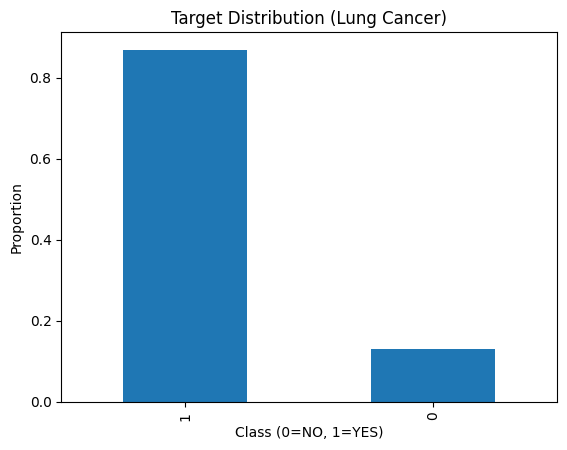

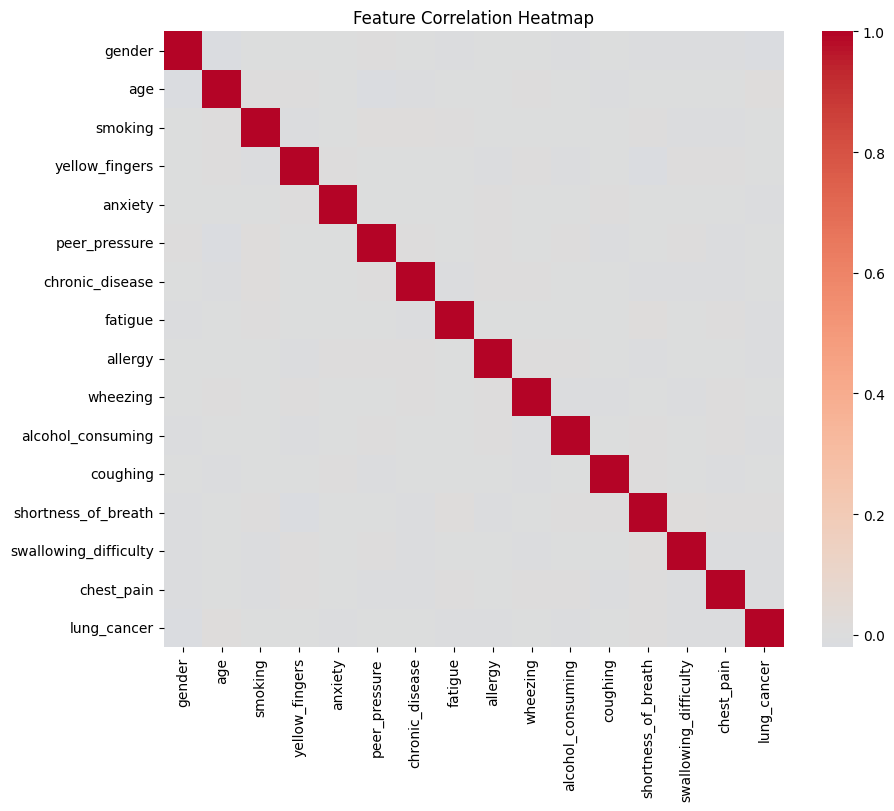

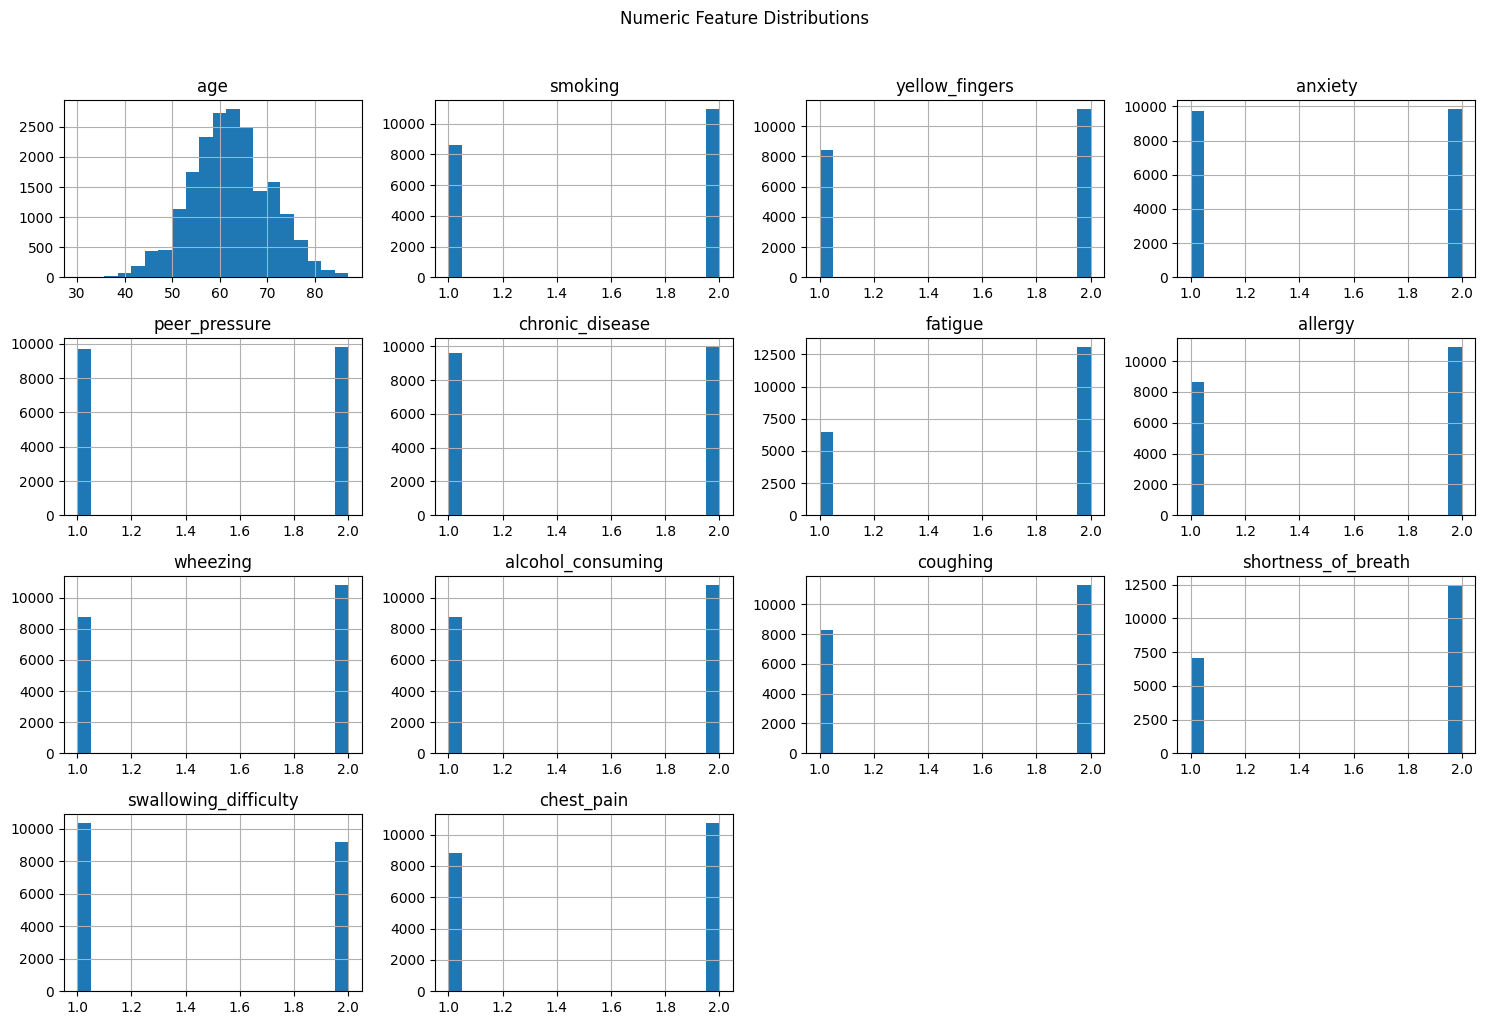


SUMMARY REPORT
Final shape: (19571, 16)
Target balance: {1: 17012, 0: 2559}
Categorical cols encoded: ['gender']
Numeric cols: ['age', 'smoking', 'yellow_fingers', 'anxiety', 'peer_pressure', 'chronic_disease', 'fatigue', 'allergy', 'wheezing', 'alcohol_consuming', 'coughing', 'shortness_of_breath', 'swallowing_difficulty', 'chest_pain']
Train/Test split: {'train_rows': 15656, 'test_rows': 3915}



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

FILE_PATH = r"C:\Users\shivakumar.kvskr\Desktop\g_sir\lcs_synthetic_20000.csv"
df = pd.read_csv(FILE_PATH)
print(f"Loaded shape: {df.shape}")

df.columns = (
    df.columns
      .str.strip()
      .str.replace(r"\s+", "_", regex=True)
      .str.replace(r"[^\w]+", "_", regex=True)
      .str.lower()
)

dupes = df.duplicated().sum()
if dupes:
    print(f"Removing {dupes} duplicate rows...")
    df = df.drop_duplicates().reset_index(drop=True)

target_col = "lung_cancer"
df[target_col] = df[target_col].str.strip().str.upper().map({"YES":1, "NO":0})

cat_cols = [c for c in df.select_dtypes(include="object").columns if c != target_col]
num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != target_col]
print("categorical columns:", cat_cols)
print("numeric columns:", num_cols)

for c in cat_cols:
    df[c] = df[c].astype('category').cat.codes

missing = df.isna().sum().sort_values(ascending=False)
print("\nMissing values:\n", missing[missing>0])

from sklearn.model_selection import train_test_split
X = df.drop(columns=[target_col])
y = df[target_col]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

fig, ax = plt.subplots()
y.value_counts(normalize=True).plot(kind='bar', ax=ax)
ax.set_title("Target Distribution (Lung Cancer)")
ax.set_xlabel("Class (0=NO, 1=YES)")
ax.set_ylabel("Proportion")
plt.show()

corr = df.corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap")
plt.show()

df[num_cols].hist(figsize=(15,10), bins=20)
plt.suptitle("Numeric Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("SUMMARY REPORT")
print(f"Final shape: {df.shape}")
print("Target balance:", y.value_counts().to_dict())
print("Categorical cols encoded:", cat_cols)
print("Numeric cols:", num_cols)
print("Train/Test split:", {"train_rows": len(X_train), "test_rows": len(X_test)})
print("="*70 + "\n")


In [6]:
print("\nChosen thresholds:", thr_dict)


Chosen thresholds: {'BalancedRF': 0.05, 'EasyEnsemble': 0.05, 'CalibratedLR': 0.05, 'XGBoost_Imb': 0.10999999999999999, 'StackingEnsemble': 0.05}


In [10]:
import numpy as np
import pandas as pd
import os
import warnings
from tqdm import tqdm
import shap
import lime
import lime.lime_tabular
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier
from sklearn.ensemble import StackingClassifier

warnings.filterwarnings("ignore")

# Load and preprocess data
FILE_PATH = r"C:\Users\shivakumar.kvskr\Desktop\g_sir\lcs_synthetic_20000.csv"
df = pd.read_csv(FILE_PATH)
df.columns = (df.columns.str.strip().str.lower().str.replace(r"\s+","_",regex=True))
df = df.drop_duplicates().reset_index(drop=True)
df["lung_cancer"] = df["lung_cancer"].str.strip().str.upper().map({"YES":1,"NO":0})
df["gender"] = df["gender"].astype("category").cat.codes

base_cols = ['age','smoking','yellow_fingers','anxiety','peer_pressure','chronic_disease',
             'fatigue','allergy','wheezing','alcohol_consuming','coughing','shortness_of_breath',
             'swallowing_difficulty','chest_pain','gender']
symptom_cols = [c for c in base_cols if c not in ['age','gender']]
df["symptom_score"] = df[symptom_cols].sum(axis=1)

X = df.drop(columns=["lung_cancer"])
y = df["lung_cancer"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

def best_threshold(clf, Xv, yv):
    proba = clf.predict_proba(Xv)[:,1]
    grid = np.linspace(0.05, 0.95, 181)
    best_t, best_f1 = 0.5, -1
    for t in tqdm(grid, desc="Threshold tuning"):
        yp = (proba >= t).astype(int)
        f1 = f1_score(yv, yp)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t

def eval_with_threshold(name, model, thr, Xs, ys):
    p = model.predict_proba(Xs)[:,1]
    yp = (p >= thr).astype(int)
    return dict(
        Model=name,
        Accuracy=accuracy_score(ys, yp),
        Precision=precision_score(ys, yp),
        Recall=recall_score(ys, yp),
        F1=f1_score(ys, yp)
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Model training with tqdm
brf = BalancedRandomForestClassifier(
    n_estimators=600, max_depth=None, min_samples_split=2, min_samples_leaf=1,
    sampling_strategy="auto", bootstrap=True, class_weight=None, random_state=42, n_jobs=-1
)
for _ in tqdm(range(1), desc="Training BalancedRF"):
    brf.fit(X_tr, y_tr)
thr_brf = best_threshold(brf, X_val, y_val)

eec = EasyEnsembleClassifier(
    n_estimators=50, random_state=42, n_jobs=-1
)
for _ in tqdm(range(1), desc="Training EasyEnsemble"):
    eec.fit(X_tr, y_tr)
thr_eec = best_threshold(eec, X_val, y_val)

pipe_lr = Pipeline([
    ("sc", StandardScaler(with_mean=False)),
    ("lr", LogisticRegression(max_iter=3000, class_weight="balanced"))
])
cal_lr = CalibratedClassifierCV(pipe_lr, method="sigmoid", cv=cv)
for _ in tqdm(range(1), desc="Training CalibratedLR"):
    cal_lr.fit(X_tr, y_tr)
thr_lr = best_threshold(cal_lr, X_val, y_val)

pos = y_train.value_counts()[1]
neg = y_train.value_counts()[0]
scale_pos = neg / pos
xgb = XGBClassifier(
    n_estimators=800, max_depth=6, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9, reg_lambda=1.0, gamma=0.0,
    scale_pos_weight=scale_pos, eval_metric="logloss", random_state=42, n_jobs=-1
)
for _ in tqdm(range(1), desc="Training XGBoost"):
    xgb.fit(X_tr, y_tr)
thr_xgb = best_threshold(xgb, X_val, y_val)

# Evaluate models
rows = []
for name, mdl, thr in [
    ("BalancedRF", brf, thr_brf),
    ("EasyEnsemble", eec, thr_eec),
    ("CalibratedLR", cal_lr, thr_lr),
    ("XGBoost_Imb", xgb, thr_xgb)
]:
    rows.append({"Split":"train", **eval_with_threshold(name, mdl, thr, X_train, y_train)})
    rows.append({"Split":"test", **eval_with_threshold(name, mdl, thr, X_test, y_test)})

res_hi = pd.DataFrame(rows)
print("\n=== HIGH-POWER MODELS (threshold-tuned) ===")
print(res_hi)

# Stacking ensemble
val_scores = []
for name, mdl, thr in [
    ("BalancedRF", brf, thr_brf),
    ("EasyEnsemble", eec, thr_eec),
    ("CalibratedLR", cal_lr, thr_lr),
    ("XGBoost_Imb", xgb, thr_xgb)
]:
    s = eval_with_threshold(name, mdl, thr, X_val, y_val)["F1"]
    val_scores.append((s, name, mdl, thr))
val_scores.sort(reverse=True)
top = val_scores[:3]

estimators = [(n, m) for _, n, m, _ in top]
meta = LogisticRegression(max_iter=3000, class_weight="balanced")
stack = StackingClassifier(
    estimators=estimators, final_estimator=meta, stack_method="predict_proba", n_jobs=-1, passthrough=True
)
for _ in tqdm(range(1), desc="Training StackingEnsemble"):
    stack.fit(X_tr, y_tr)
thr_stack = best_threshold(stack, X_val, y_val)

rows2 = []
rows2.append({"Split":"train", **eval_with_threshold("StackingEnsemble", stack, thr_stack, X_train, y_train)})
rows2.append({"Split":"test", **eval_with_threshold("StackingEnsemble", stack, thr_stack, X_test, y_test)})
res_stack = pd.DataFrame(rows2)

print("\n=== STACKING ENSEMBLE (top-3) ===")
print(res_stack)

thr_dict = {
    "BalancedRF": float(thr_brf),
    "EasyEnsemble": float(thr_eec),
    "CalibratedLR": float(thr_lr),
    "XGBoost_Imb": float(thr_xgb),
    "StackingEnsemble": float(thr_stack),
}
print("\nChosen thresholds:", thr_dict)

# SHAP and LIME for Stacking Ensemble
print("\n=== SHAP and LIME Analysis for StackingEnsemble ===")

# SHAP Analysis
explainer = shap.KernelExplainer(lambda x: stack.predict_proba(x)[:,1], X_tr.sample(100, random_state=42))
shap_values = explainer.shap_values(X_test.sample(100, random_state=42))
shap.summary_plot(shap_values, X_test.sample(100, random_state=42), feature_names=X.columns, show=False)

# LIME Analysis
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X_tr.values, 
    feature_names=X.columns, 
    class_names=["No Cancer", "Cancer"], 
    mode="classification"
)
for i in tqdm(range(3), desc="LIME Explanations"):
    instance = X_test.iloc[i]
    exp = lime_explainer.explain_instance(instance.values, stack.predict_proba, num_features=10)
    print(f"\nLIME Explanation for instance {i}:")
    exp.show_in_notebook(show_table=True)

Threshold tuning: 100%|█████████████████████████████████████████████████████████████| 181/181 [00:00<00:00, 412.28it/s]



=== HIGH-POWER MODELS (threshold-tuned) ===
   Split         Model  Accuracy  Precision    Recall        F1
0  train    BalancedRF  0.869315   0.869307  1.000000  0.930085
1   test    BalancedRF  0.869221   0.869221  1.000000  0.930036
2  train  EasyEnsemble  0.869251   0.869251  1.000000  0.930053
3   test  EasyEnsemble  0.869221   0.869221  1.000000  0.930036
4  train  CalibratedLR  0.869251   0.869251  1.000000  0.930053
5   test  CalibratedLR  0.869221   0.869221  1.000000  0.930036
6  train   XGBoost_Imb  0.870848   0.870784  0.999780  0.930834
7   test   XGBoost_Imb  0.867688   0.869020  0.998237  0.929158


Threshold tuning: 100%|█████████████████████████████████████████████████████████████| 181/181 [00:00<00:00, 477.60it/s]



=== STACKING ENSEMBLE (top-3) ===
   Split             Model  Accuracy  Precision  Recall        F1
0  train  StackingEnsemble  0.869251   0.869251     1.0  0.930053
1   test  StackingEnsemble  0.869221   0.869221     1.0  0.930036

Chosen thresholds: {'BalancedRF': 0.05, 'EasyEnsemble': 0.05, 'CalibratedLR': 0.05, 'XGBoost_Imb': 0.10999999999999999, 'StackingEnsemble': 0.05}

=== SHAP and LIME Analysis for StackingEnsemble ===


  0%|          | 0/100 [00:00<?, ?it/s]

LIME Explanations:   0%|                                                                         | 0/3 [00:00<?, ?it/s]


LIME Explanation for instance 0:


LIME Explanations:  33%|█████████████████████▋                                           | 1/3 [00:00<00:01,  1.22it/s]


LIME Explanation for instance 1:


LIME Explanations:  67%|███████████████████████████████████████████▎                     | 2/3 [00:01<00:00,  1.18it/s]


LIME Explanation for instance 2:


LIME Explanations: 100%|█████████████████████████████████████████████████████████████████| 3/3 [00:02<00:00,  1.22it/s]


Training Balanced Random Forest...


Threshold tuning: 100%|█████████████████████████████████████████████████████████████| 181/181 [00:00<00:00, 293.73it/s]


Training EasyEnsemble...


Threshold tuning: 100%|█████████████████████████████████████████████████████████████| 181/181 [00:00<00:00, 288.90it/s]


Training Calibrated Logistic Regression...


Threshold tuning: 100%|█████████████████████████████████████████████████████████████| 181/181 [00:00<00:00, 334.70it/s]


Training XGBoost...


Threshold tuning: 100%|█████████████████████████████████████████████████████████████| 181/181 [00:00<00:00, 305.64it/s]



=== MODEL PERFORMANCE ===
   Split         Model  Accuracy  Precision    Recall        F1
0  train    BalancedRF  0.869251   0.869251  1.000000  0.930053
1   test    BalancedRF  0.869221   0.869221  1.000000  0.930036
2  train  EasyEnsemble  0.869251   0.869251  1.000000  0.930053
3   test  EasyEnsemble  0.869221   0.869221  1.000000  0.930036
4  train  CalibratedLR  0.869251   0.869251  1.000000  0.930053
5   test  CalibratedLR  0.869221   0.869221  1.000000  0.930036
6  train   XGBoost_IMB  0.870848   0.870784  0.999780  0.930834
7   test   XGBoost_IMB  0.867688   0.869020  0.998237  0.929158

Training Stacking Ensemble...


Threshold tuning: 100%|█████████████████████████████████████████████████████████████| 181/181 [00:00<00:00, 427.69it/s]



=== STACKING RESULTS ===
   Split             Model  Accuracy  Precision  Recall        F1
0  train  StackingEnsemble  0.869251   0.869251     1.0  0.930053
1   test  StackingEnsemble  0.869221   0.869221     1.0  0.930036

=== SHAP ANALYSIS ===
Preparing background and test samples...
Building SHAP KernelExplainer...
Computing SHAP values...


  0%|          | 0/100 [00:00<?, ?it/s]

Showing SHAP Summary Plot...


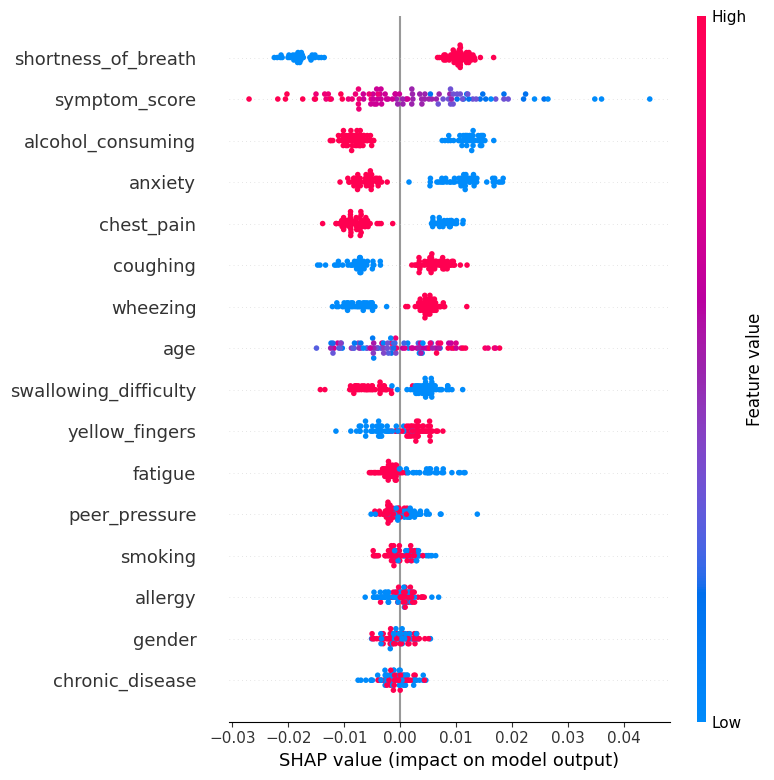

Showing SHAP Bar Plot...


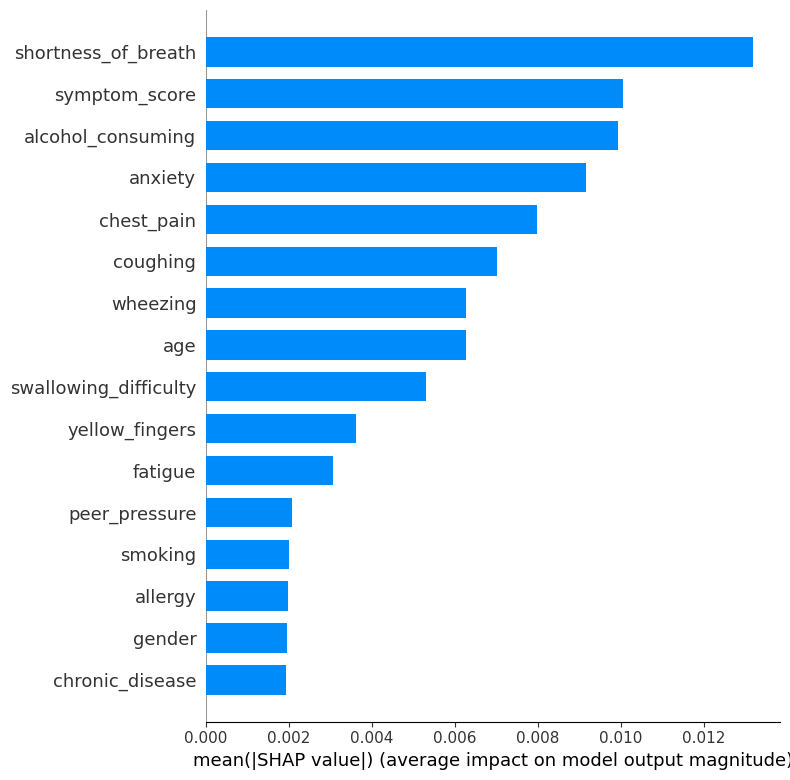

Showing SHAP Force Plot...


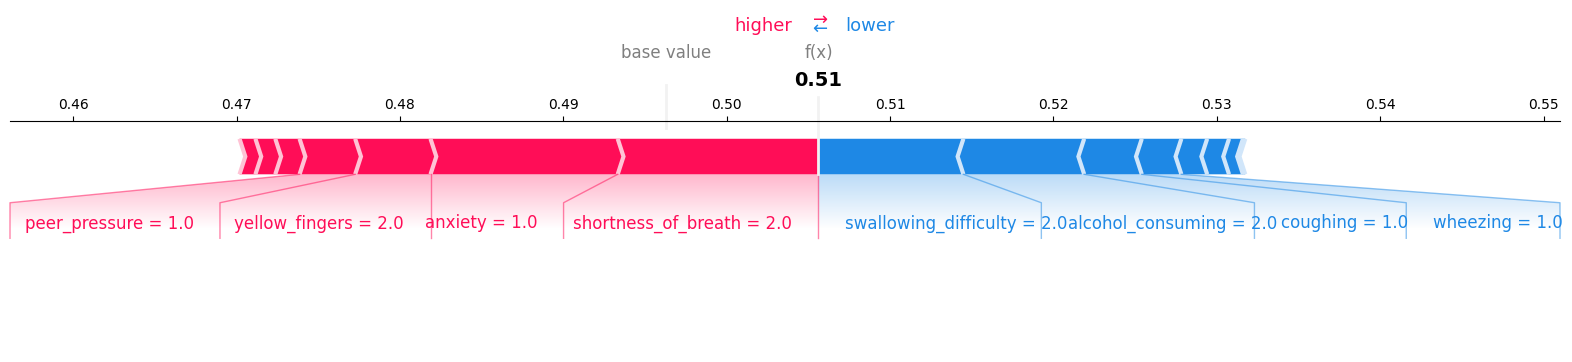

Showing SHAP Decision Plot...


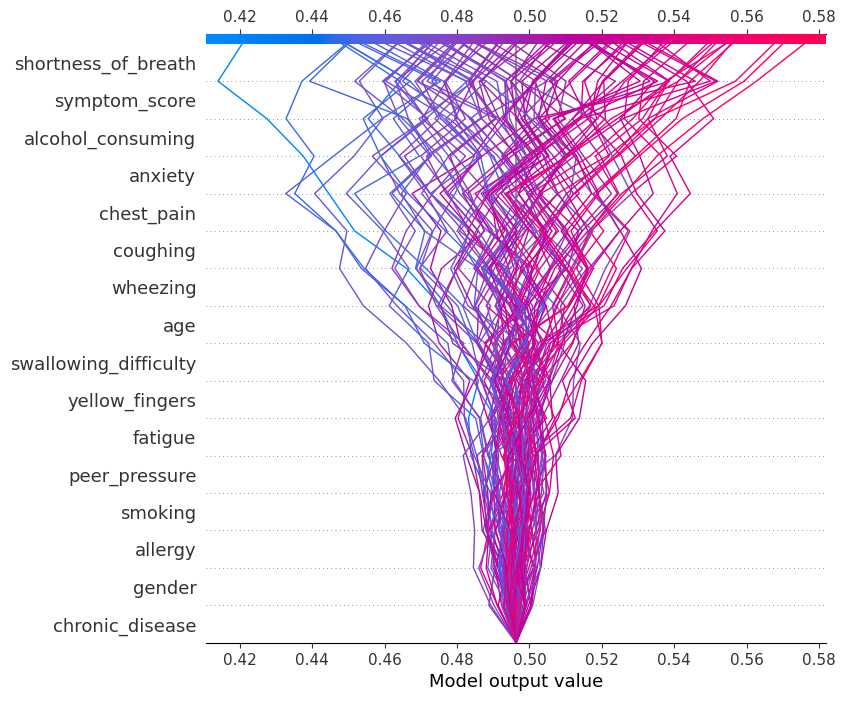

Showing SHAP Waterfall Plot...


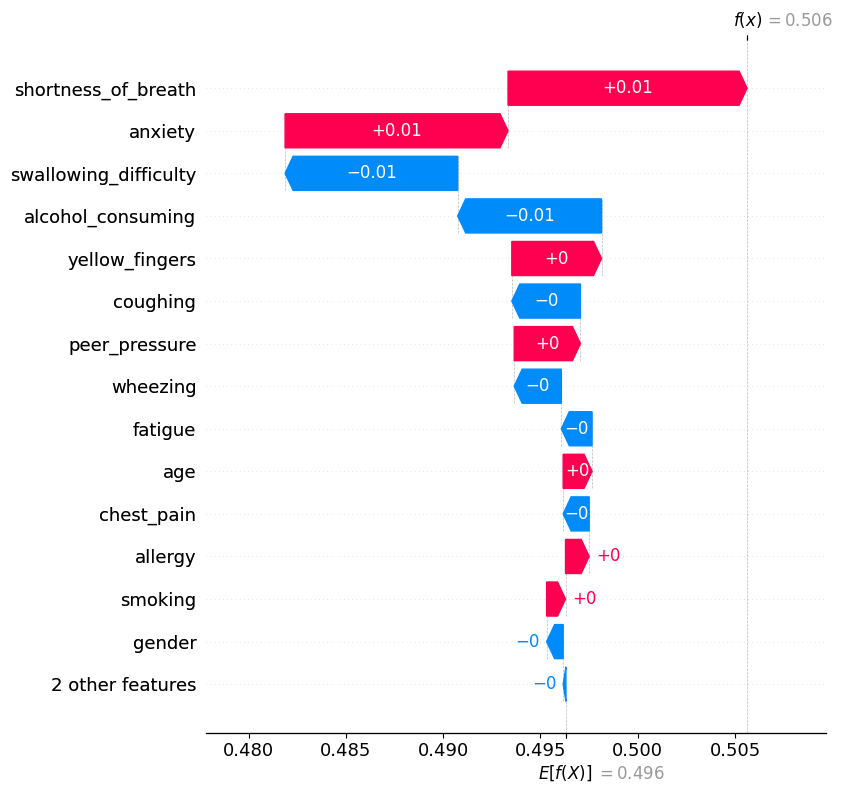

Showing SHAP Dependence Plots...
Dependence Plot for: shortness_of_breath


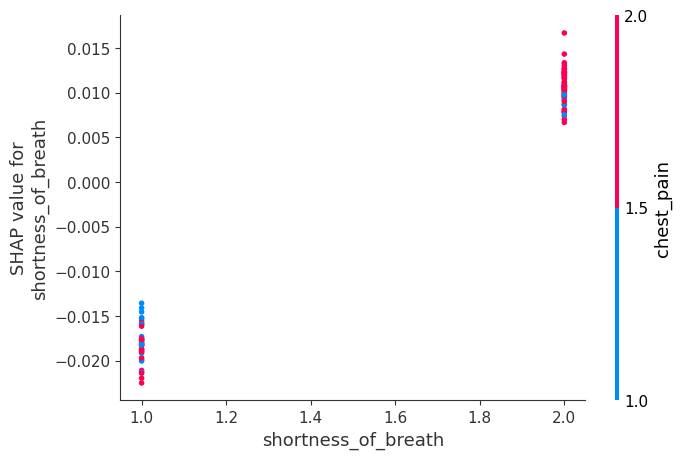

Dependence Plot for: symptom_score


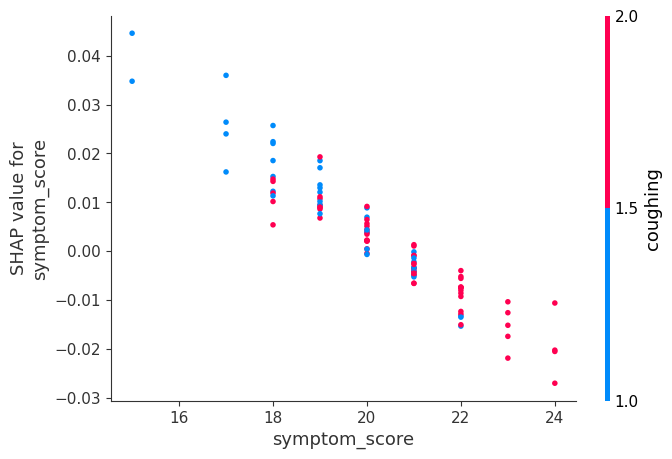

Dependence Plot for: alcohol_consuming


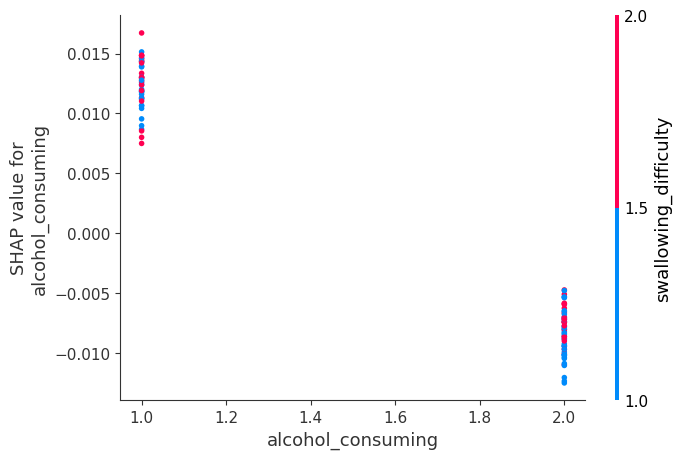

Dependence Plot for: anxiety


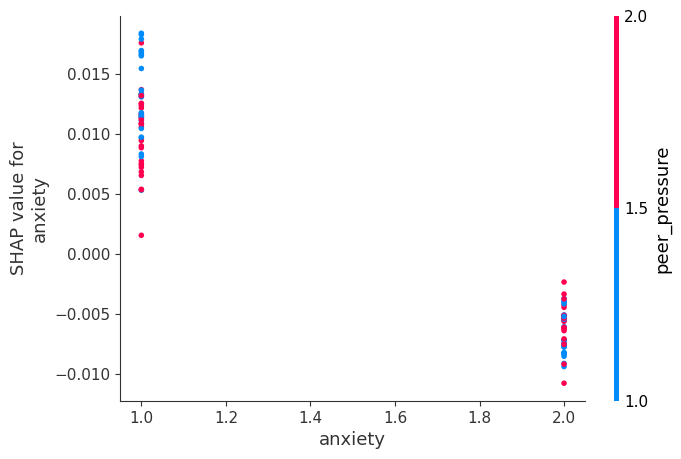

Dependence Plot for: chest_pain


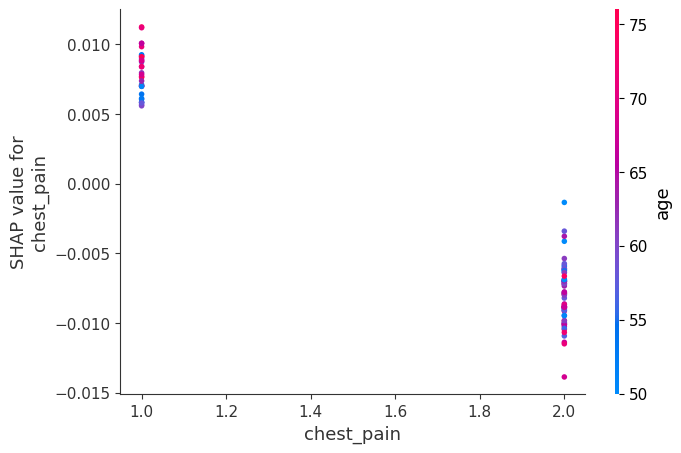

In [7]:
import numpy as np
import pandas as pd
import warnings
from tqdm import tqdm
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier
from imblearn.ensemble import BalancedRandomForestClassifier, EasyEnsembleClassifier
from sklearn.ensemble import StackingClassifier

warnings.filterwarnings("ignore")

# =====================================================
#                LOAD AND PREPROCESS DATA
# =====================================================

FILE_PATH = r"C:\Users\shivakumar.kvskr\Desktop\g_sir\lcs_synthetic_20000.csv"
df = pd.read_csv(FILE_PATH)

df.columns = (
    df.columns.str.strip()
              .str.lower()
              .str.replace(r"\s+", "_", regex=True)
)

df = df.drop_duplicates().reset_index(drop=True)

df["lung_cancer"] = df["lung_cancer"].str.strip().str.upper().map({"YES": 1, "NO": 0})
df["gender"] = df["gender"].astype("category").cat.codes

base_cols = [
    'age','smoking','yellow_fingers','anxiety','peer_pressure','chronic_disease',
    'fatigue','allergy','wheezing','alcohol_consuming','coughing','shortness_of_breath',
    'swallowing_difficulty','chest_pain','gender'
]

symptom_cols = [c for c in base_cols if c not in ['age', 'gender']]
df["symptom_score"] = df[symptom_cols].sum(axis=1)

X = df.drop(columns=["lung_cancer"])
y = df["lung_cancer"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)


def best_threshold(clf, Xv, yv):
    proba = clf.predict_proba(Xv)[:, 1]
    grid = np.linspace(0.05, 0.95, 181)
    best_t, best_f1 = 0.5, -1
    for t in tqdm(grid, desc="Threshold tuning"):
        yp = (proba >= t).astype(int)
        f1 = f1_score(yv, yp)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return best_t

def eval_with_threshold(name, model, thr, Xs, ys):
    p = model.predict_proba(Xs)[:, 1]
    yp = (p >= thr).astype(int)
    return dict(
        Model=name,
        Accuracy=accuracy_score(ys, yp),
        Precision=precision_score(ys, yp),
        Recall=recall_score(ys, yp),
        F1=f1_score(ys, yp)
    )

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =====================================================
#                 MODEL TRAINING
# =====================================================

print("Training Balanced Random Forest...")
brf = BalancedRandomForestClassifier(
    n_estimators=600, random_state=42, n_jobs=-1
)
brf.fit(X_tr, y_tr)
thr_brf = best_threshold(brf, X_val, y_val)

print("Training EasyEnsemble...")
eec = EasyEnsembleClassifier(
    n_estimators=50, random_state=42, n_jobs=-1
)
eec.fit(X_tr, y_tr)
thr_eec = best_threshold(eec, X_val, y_val)

print("Training Calibrated Logistic Regression...")
pipe_lr = Pipeline([
    ("sc", StandardScaler(with_mean=False)),
    ("lr", LogisticRegression(max_iter=3000, class_weight="balanced"))
])
cal_lr = CalibratedClassifierCV(pipe_lr, cv=cv, method="sigmoid")
cal_lr.fit(X_tr, y_tr)
thr_lr = best_threshold(cal_lr, X_val, y_val)

print("Training XGBoost...")
pos = y_train.sum()
neg = len(y_train) - pos
scale_pos = neg / pos

xgb = XGBClassifier(
    n_estimators=800, max_depth=6, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=scale_pos, eval_metric="logloss",
    random_state=42, n_jobs=-1
)
xgb.fit(X_tr, y_tr)
thr_xgb = best_threshold(xgb, X_val, y_val)

rows = []
for name, mdl, thr in [
    ("BalancedRF", brf, thr_brf),
    ("EasyEnsemble", eec, thr_eec),
    ("CalibratedLR", cal_lr, thr_lr),
    ("XGBoost_IMB", xgb, thr_xgb)
]:
    rows.append({"Split": "train", **eval_with_threshold(name, mdl, thr, X_train, y_train)})
    rows.append({"Split": "test", **eval_with_threshold(name, mdl, thr, X_test, y_test)})

res_models = pd.DataFrame(rows)
print("\n=== MODEL PERFORMANCE ===")
print(res_models)


val_scores = []
for name, mdl, thr in [
    ("BalancedRF", brf, thr_brf),
    ("EasyEnsemble", eec, thr_eec),
    ("CalibratedLR", cal_lr, thr_lr),
    ("XGBoost_IMB", xgb, thr_xgb)
]:
    val_scores.append((eval_with_threshold(name, mdl, thr, X_val, y_val)["F1"], name, mdl))

val_scores.sort(reverse=True)
top3 = val_scores[:3]

estimators = [(n, m) for _, n, m in top3]

meta = LogisticRegression(max_iter=3000, class_weight="balanced")
stack = StackingClassifier(
    estimators=estimators,
    final_estimator=meta,
    stack_method="predict_proba",
    passthrough=True,
    n_jobs=-1
)

print("\nTraining Stacking Ensemble...")
stack.fit(X_tr, y_tr)
thr_stack = best_threshold(stack, X_val, y_val)

stack_results = [
    {"Split": "train", **eval_with_threshold("StackingEnsemble", stack, thr_stack, X_train, y_train)},
    {"Split": "test", **eval_with_threshold("StackingEnsemble", stack, thr_stack, X_test, y_test)},
]
print("\n=== STACKING RESULTS ===")
print(pd.DataFrame(stack_results))

# =====================================================
#                     SHAP ANALYSIS
# =====================================================

print("\n=== SHAP ANALYSIS ===")
print("Preparing background and test samples...")

X_shap_background = X.sample(100, random_state=42)
X_shap_test = X.sample(100, random_state=101)

print("Building SHAP KernelExplainer...")
explainer = shap.KernelExplainer(
    lambda v: stack.predict_proba(v)[:, 1],
    X_shap_background
)

print("Computing SHAP values...")
shap_values = explainer.shap_values(X_shap_test)

# 1. Summary Plot
print("Showing SHAP Summary Plot...")
shap.summary_plot(shap_values, X_shap_test, feature_names=X.columns, show=True)

# 2. Bar Plot
print("Showing SHAP Bar Plot...")
shap.summary_plot(shap_values, X_shap_test, feature_names=X.columns, plot_type="bar", show=True)

# 3. Force Plot
shap.initjs()
print("Showing SHAP Force Plot...")
shap.force_plot(explainer.expected_value, shap_values[0], X_shap_test.iloc[0], matplotlib=True)

# 4. Decision Plot
# 4. Decision Plot
print("Showing SHAP Decision Plot...")
shap.decision_plot(
    explainer.expected_value,
    shap_values,
    X_shap_test,
    feature_names=list(X.columns),  # FIXED HERE
    show=True
)

# 5. Waterfall Plot
print("Showing SHAP Waterfall Plot...")
shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value,
    shap_values[0],
    feature_names=X.columns,
    max_display=15
)

# 6. Dependence Plots (Top 5 Features)
print("Showing SHAP Dependence Plots...")
mean_abs = np.abs(shap_values).mean(axis=0)
top5 = np.argsort(mean_abs)[-5:][::-1]

for idx in top5:
    feat = X.columns[idx]
    print("Dependence Plot for:", feat)
    shap.dependence_plot(
        feat,
        shap_values,
        X_shap_test,
        feature_names=X.columns,
        show=True
    )
